# 06 · 提取卫星图特征（GreenPath）

**这一步做什么**：用**预训练好的视觉编码器**把每张卫星图变成一串数字（特征向量），并缓存下来。07 里的模型只用这些数字，不再碰图片。

**"基础模型"是什么、怎么用**：编码器是别人在海量图片上训练好的"看图专家"，已经学会了识别边缘、纹理、树冠、屋顶、道路这些东西。我们**不训练它**（"冻结"），只让它看每张卫星图，输出一个几百维的向量，概括这张图的内容。这些数字单看没有直观含义，但包含了图片信息，07 里一个很简单的线性公式就能把它们"翻译"成 8 个体验分数。

三个编码器（07 里按交叉验证挑最好的）：

| 名字 | 模型 | 特点 | 特征维度 |
|---|---|---|---|
| `resnet50` | ResNet-50（ImageNet 预训练，`timm`） | 最经典的起点 | 2048 |
| `dinov2_s` | DINOv2 ViT-S/14（`timm`） | 通用视觉特征很强 | 384 |
| `clip_b16` | CLIP ViT-B/16（LAION-2B，`open_clip`） | 语义特征强 | 512 |

| | 路径（相对数据根目录） |
|---|---|
| 输入：冻结的数据集 | `datasets/{版本}/dataset.parquet`、`processed/tiles/*.png` |
| 输出：图像特征（缓存） | `embeddings/{版本}/{编码器}_tta.parquet` |
| 输出：提取记录（设备、版本、耗时） | `embeddings/{版本}/meta.json` |
| 输出：运行记录 | `runs/{时间戳}/06_embeddings_manifest.json` |

**预处理**：256×256 的卫星图中心裁成 224×224，按各模型自己的均值和方差归一化。
**测试时增强（TTA）**：俯视图没有"上下"，所以对每张图做 8 种旋转 / 翻转，特征取平均，更稳，代价是慢 8 倍（Mac 的 GPU 上仍然只要几分钟）。

**为什么单独一个 notebook**：PyTorch 和 LightGBM 在 Mac 上不能放进同一个进程（两者各带一份 OpenMP 库，同时加载会崩溃）。所以提特征（只用 torch）放在这里，训练基线（只用 LightGBM / sklearn）放在 07。这也对应以后的两个容器：一个需要 PyTorch（可能还要 GPU），一个不需要。

**第一次运行会下载权重**（约 0.8 GB，存在 `~/.cache/huggingface`），之后读缓存。可断点续跑：已经缓存的编码器会跳过。

## 1. 安装依赖（只在 Colab 里会执行）

In [1]:
import sys, subprocess
if "google.colab" in sys.modules:      # 只有在 Colab 里才自动安装；本地环境请提前装好
    subprocess.run([sys.executable, "-m", "pip", "-q", "install", "torch", "torchvision", "timm", "open_clip_torch", "pandas", "pyarrow", "gcsfs", "matplotlib", "pillow", "tqdm", "fsspec"], check=True)

## 2. 配置
- `BACKBONES`：要提取的编码器。
- `TTA`：是否做 8 种旋转 / 翻转取平均。**改了它，07 里的 `TTA` 也要同步**（决定读哪个缓存文件）。
- `BATCH`：一次处理多少张图（内存不够就调小）。

In [2]:
DATASET_VERSION = "v1"
BACKBONES = ["resnet50", "dinov2_s", "clip_b16"]
TTA = True
BATCH = 64

STORAGE = "local"                              # "local" | "gcs" | "drive"
GCS_ROOT = "gs://greenpath-data"
DRIVE_ROOT = "/content/drive/MyDrive/greenpath-data"
LOCAL_ROOT = "./data"

## 3. 连接存储，读入数据集

In [3]:
import os, io, json, datetime
import fsspec
import pandas as pd

STORAGE_OPTS = {}
if STORAGE == "gcs":
    try:
        from google.colab import auth
        auth.authenticate_user()                 # Colab 里登录；本地请先 gcloud auth application-default login
    except ImportError:
        pass
    ROOT = GCS_ROOT
    STORAGE_OPTS = {"token": "google_default"}
    fs = fsspec.filesystem("gcs", **STORAGE_OPTS)
elif STORAGE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    ROOT = DRIVE_ROOT
    fs = fsspec.filesystem("file")
else:
    ROOT = os.environ.get("GREENPATH_ROOT", LOCAL_ROOT)   # 以后容器里用环境变量指定数据目录
    fs = fsspec.filesystem("file")

def path(*parts):
    # 拼出数据根目录下的完整路径，例如 path("processed", "cells.parquet")
    return "/".join([ROOT.rstrip("/"), *parts])

def makedirs(p):
    if STORAGE != "gcs":            # GCS 没有真正的目录，不需要创建
        os.makedirs(p, exist_ok=True)

def read_parquet(p):
    return pd.read_parquet(p, storage_options=STORAGE_OPTS or None)

def write_parquet(df, p):
    df.to_parquet(p, index=False, storage_options=STORAGE_OPTS or None)

def write_manifest(manifest, name):
    run_ts = datetime.datetime.utcnow().strftime("%Y-%m-%dT%H-%M")
    makedirs(path("runs", run_ts))
    with fs.open(path("runs", run_ts, name), "w") as f:
        json.dump(manifest, f, indent=2, ensure_ascii=False)
    return manifest

try:                                          # 图里的中文用系统自带的中文字体显示
    import matplotlib
    matplotlib.rcParams["font.sans-serif"] = ["PingFang SC", "Heiti SC", "Arial Unicode MS", "Noto Sans CJK SC",
                                              "Microsoft YaHei", "SimHei", "DejaVu Sans"]
    matplotlib.rcParams["axes.unicode_minus"] = False
except ImportError:
    pass

now_iso = lambda: datetime.datetime.utcnow().isoformat(timespec="seconds") + "Z"
print("数据根目录:", ROOT)

数据根目录: ./data


In [4]:
import numpy as np, time, os
os.environ.setdefault("PYTORCH_ENABLE_MPS_FALLBACK", "1")          # Mac GPU 缺某个算子时自动退回 CPU
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

# ⚠ 这个 notebook 里不要导入 lightgbm / sklearn：它们和 torch 各带一份 OpenMP 库，同一进程里同时加载会崩溃（macOS）。
ds = read_parquet(path(f"datasets/{DATASET_VERSION}", "dataset.parquet"))[["cell_id", "tile_path"]].sort_values("cell_id").reset_index(drop=True)
print(f"数据集 {DATASET_VERSION}：{len(ds)} 个格子")

数据集 v1：1012 个格子


## 4. 读取卫星图并提取特征

In [5]:
import torch
from PIL import Image

DEVICE = "mps" if torch.backends.mps.is_available() else ("cuda" if torch.cuda.is_available() else "cpu")
IMAGENET = ([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
CLIPNORM = ([0.48145466, 0.4578275, 0.40821073], [0.26862954, 0.26130258, 0.27577711])
SOURCES = {"resnet50": "timm: resnet50.a1_in1k", "dinov2_s": "timm: vit_small_patch14_dinov2.lvd142m",
           "clip_b16": "open_clip: ViT-B-16 / laion2b_s34b_b88k"}
print("设备：", DEVICE)

def load_images(df, crop=224):
    out = np.zeros((len(df), crop, crop, 3), np.uint8)
    for i, p in enumerate(tqdm(df.tile_path, desc="读取卫星图")):
        with fs.open(path(p), "rb") as f:
            im = Image.open(f).convert("RGB")
        w, h = im.size; l, t = (w - crop) // 2, (h - crop) // 2
        out[i] = np.asarray(im.crop((l, t, l + crop, t + crop)))
    return out

def make_backbone(name):
    import timm
    if name == "resnet50":
        m = timm.create_model("resnet50.a1_in1k", pretrained=True, num_classes=0); return m, m, IMAGENET
    if name == "dinov2_s":
        m = timm.create_model("vit_small_patch14_dinov2.lvd142m", pretrained=True, num_classes=0, img_size=224); return m, m, IMAGENET
    if name == "clip_b16":
        import open_clip
        m, _, _ = open_clip.create_model_and_transforms("ViT-B-16", pretrained="laion2b_s34b_b88k")
        return m, m.encode_image, CLIPNORM
    raise ValueError(name)

@torch.no_grad()
def embed(name, imgs, tta=TTA, bs=BATCH):
    model, fn, (mean, std) = make_backbone(name)
    model.eval().to(DEVICE)
    mean = torch.tensor(mean, device=DEVICE).view(1, 3, 1, 1); std = torch.tensor(std, device=DEVICE).view(1, 3, 1, 1)
    outs = []
    for i in tqdm(range(0, len(imgs), bs), desc=f"提特征 {name}"):
        x = torch.from_numpy(imgs[i:i + bs]).to(DEVICE).permute(0, 3, 1, 2).float() / 255
        x = (x - mean) / std
        views = [x]
        if tta:                                  # 4 个旋转 × 是否翻转 = 8 种视角，特征取平均
            views = [torch.rot90(x, k, (2, 3)) for k in range(4)] + [torch.rot90(torch.flip(x, (3,)), k, (2, 3)) for k in range(4)]
        outs.append(torch.stack([fn(v) for v in views]).mean(0).float().cpu().numpy())
    del model
    return np.concatenate(outs)

meta_rel = f"embeddings/{DATASET_VERSION}/meta.json"
meta = json.load(fs.open(path(meta_rel), "r")) if fs.exists(path(meta_rel)) else {}
IMG, EMB = None, {}
for name in BACKBONES:
    rel = f"embeddings/{DATASET_VERSION}/{name}{'_tta' if TTA else ''}.parquet"
    if fs.exists(path(rel)):
        e = read_parquet(path(rel)).set_index("cell_id").reindex(ds.cell_id)
        EMB[name] = e.values.astype("float32")
        print(f"{name}: 读取缓存 {EMB[name].shape}")
        continue
    if IMG is None:
        IMG = load_images(ds)
    t0 = time.time()
    EMB[name] = embed(name, IMG).astype("float32")
    makedirs(path("embeddings", DATASET_VERSION))
    out = pd.DataFrame(EMB[name], columns=[f"e{i}" for i in range(EMB[name].shape[1])]); out.insert(0, "cell_id", ds.cell_id.values)
    write_parquet(out, path(rel))
    meta[name] = {"source": SOURCES[name], "dim": int(EMB[name].shape[1]), "tta": TTA, "device": DEVICE, "seconds": round(time.time() - t0, 1),
                  "torch": torch.__version__, "n": int(len(ds)), "extracted_at": now_iso()}
    with fs.open(path(meta_rel), "w") as f:
        json.dump(meta, f, indent=2)
    print(f"{name}: {EMB[name].shape}，{time.time() - t0:.0f} 秒，已缓存")

设备： mps
resnet50: 读取缓存 (1012, 2048)
dinov2_s: 读取缓存 (1012, 384)
clip_b16: 读取缓存 (1012, 512)


## 5. 检查：特征有没有抓到"相似的地方"
特征本身是一串看不懂的数字，所以做一个直观的检查：随机挑几张卫星图，在特征空间里找**最相似的 3 张**（余弦相似度）。如果特征有意义，最相似的图看起来应该也像（都是树林、都是密集屋顶、都是水边……）。每一行是一个编码器，第一列是查询图。

缺失值个数： {'resnet50': 0, 'dinov2_s': 0, 'clip_b16': 0} | 特征维度： {'resnet50': 2048, 'dinov2_s': 384, 'clip_b16': 512}


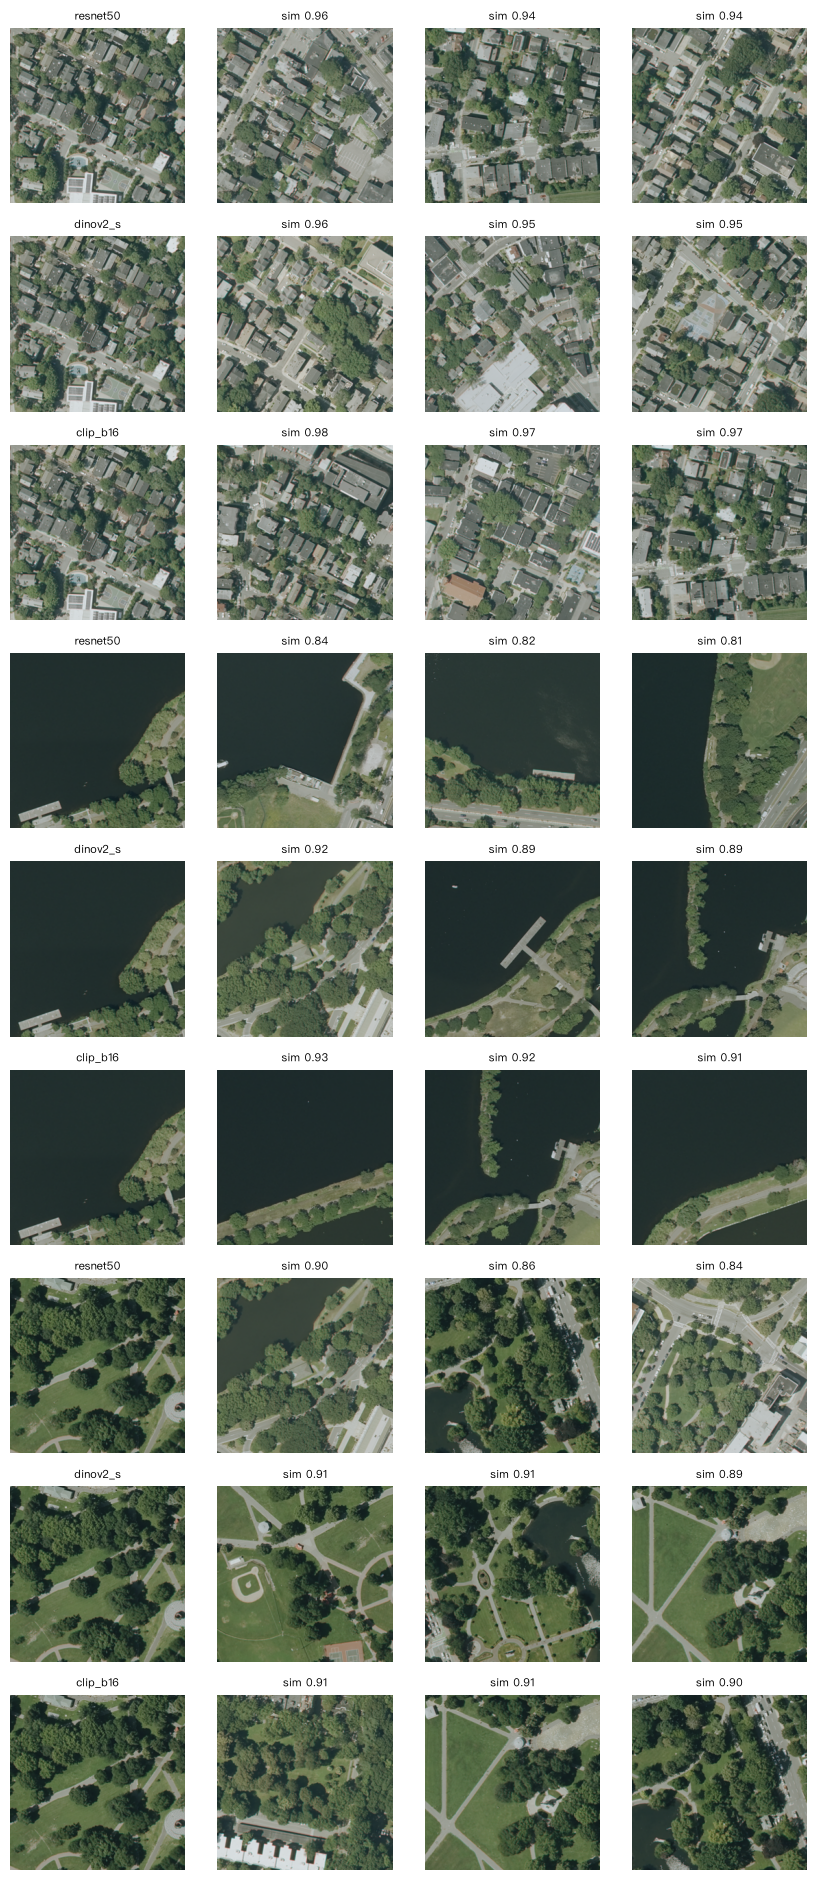

In [6]:
bad = {n: int(np.isnan(e).sum()) for n, e in EMB.items()}
print("缺失值个数：", bad, "| 特征维度：", {n: e.shape[1] for n, e in EMB.items()})
assert all(v == 0 for v in bad.values()), "特征里有 NaN"

rng = np.random.default_rng(7)
queries = rng.choice(len(ds), 3, replace=False)
rows = len(EMB) * len(queries)
fig, axes = plt.subplots(rows, 4, figsize=(8.5, 2.1 * rows))
r = 0
for q in queries:
    for name, E in EMB.items():
        En = E / np.linalg.norm(E, axis=1, keepdims=True)
        sim = En @ En[q]; nn = np.argsort(-sim)[:4]            # 第一个是它自己
        for c, i in enumerate(nn):
            with fs.open(path(ds.tile_path[i]), "rb") as f:
                axes[r, c].imshow(Image.open(f))
            axes[r, c].axis("off")
            axes[r, c].set_title(f"{name}" if c == 0 else f"sim {sim[i]:.2f}", fontsize=8)
        r += 1
plt.tight_layout(); plt.show()

## 6. 运行记录

In [7]:
write_manifest({"step": "06_embeddings", "dataset_version": DATASET_VERSION, "backbones": BACKBONES, "tta": TTA,
                "device": DEVICE, "n_cells": int(len(ds)), "dims": {n: int(e.shape[1]) for n, e in EMB.items()},
                "outputs": [f"embeddings/{DATASET_VERSION}/"], "finished_at": now_iso()}, "06_embeddings_manifest.json")
print("完成：", f"embeddings/{DATASET_VERSION}/")

完成： embeddings/v1/


## 下一步
- 下一个 notebook：`07_baselines`，读取这里缓存的特征，训练 B0、B1、M1、M3 并评估。
- 想试别的编码器（例如遥感专用的 SatlasPretrain）：在 `make_backbone` 里加一个分支，把名字加进 `BACKBONES`，07 里同步即可。